<a href="https://colab.research.google.com/github/Nayeem-294/CNN-Group09-Pneumonia-Detection/blob/main/CNN_Group09_Submission3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Project - Submission 3: Custom Convolutional Neural Network Trained from Scratch

**Project:** Pneumonia Detection from Chest X-Ray Images Using Convolutional Neural Networks

**Group No:** 09

| Name | Student ID |
|---|---|
| Nayeem Ahmed | 2024-1-60-294 |
| Mahbuba Hoque Tabassum | 2023-2-60-030 |
| Sharmin Zaman Setu | 2023-3-60-476 |
| SM Erbajul Hasan | 2023-3-60-010 |

## Objective
In Submission 2 we adapted ImageNet-pretrained networks to chest X-ray classification. In this submission we instead design a **custom CNN and train it entirely from scratch**, with randomly initialised weights, on the Kermany et al. (2018) chest X-ray dataset. The task is binary classification: **NORMAL** versus **PNEUMONIA**, with PNEUMONIA as the positive class.

## Approach
- **Architecture:** four convolutional blocks (Conv2D + Batch Normalisation + ReLU, then max pooling), followed by global average pooling and a fully connected classifier.
- **Consistency:** the data split, class weighting, augmentation, optimiser and evaluation metrics are the same as in Submission 2, so the results are directly comparable with the pretrained models.
- **Regularisation:** data augmentation, dropout, batch normalisation, and **early stopping on validation loss with a minimum of 5 epochs**.
- **Monitoring:** training and validation loss and accuracy are plotted together to detect overfitting.



## 1. Environment Setup
We first confirm that TensorFlow is installed and that a GPU is available. Training a CNN on 224 x 224 images is much faster on a GPU than on a CPU.

In [ ]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "NO GPU found - use Runtime > Change runtime type > T4 GPU (CPU will be very slow)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.1 Dataset Download
The dataset is the *Chest X-Ray Images (Pneumonia)* collection (Kermany et al., 2018), downloaded from Kaggle through the Kaggle API. The notebook asks for  personal `kaggle.json` token. This token is private and must never be committed to GitHub. The download is skipped if the data is already present in the session.

In [ ]:
import os, sys, time, json, subprocess
from pathlib import Path

if not Path("chest_xray_data").exists():
    from google.colab import files
    print("Upload your kaggle.json file:")
    up = files.upload()
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    with open(os.path.expanduser("~/.kaggle/kaggle.json"), "wb") as f:
        f.write(up["kaggle.json"])
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                    "-p", "chest_xray_data", "--unzip"], check=True)

def find_root(base="chest_xray_data"):
    for p in Path(base).rglob("train"):
        if p.is_dir() and (p.parent / "test").is_dir() and "__MACOSX" not in str(p):
            return p.parent
    raise FileNotFoundError("Could not find train/test folders")

DATA_DIR = find_root()
print("Dataset root:", DATA_DIR)

Upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Dataset root: chest_xray_data/chest_xray


### 1.2 Libraries and Hyperparameters
All hyperparameters are defined in a single place and are **kept constant throughout the notebook**, which ensures a consistent and reproducible experiment:

| Hyperparameter | Value |
|---|---|
| Input size | 224 x 224 x 3 |
| Batch size | 32 |
| Optimiser | Adam |
| Initial learning rate | 1e-3 |
| Maximum epochs | 50 (upper limit only) |
| Minimum epochs before early stopping | 5 |
| Early-stopping patience | 7 epochs |
| Validation fraction | 15% of the training folder |
| Random seed | 42 |

`MAX_EPOCHS` is only a ceiling. In practice, early stopping decides when training ends.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, roc_auc_score)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers import Adam

MODEL_NAME = "CustomCNN"
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50          # upper limit; early stopping decides the real number
MIN_EPOCHS = 5           # early stopping cannot stop before this many epochs
PATIENCE = 7             # epochs without validation-loss improvement before stopping
VAL_FRACTION = 0.15
CLASSES = ["NORMAL", "PNEUMONIA"]   # label 0 = NORMAL, label 1 = PNEUMONIA (positive class)

tf.keras.utils.set_random_seed(SEED)

## 2. Data Preparation
The original dataset provides `train`, `val` and `test` folders. The original validation folder contains only **16 images**, which is too small for reliable model selection. We therefore:

- take a **stratified 15% sample of the training folder** as our validation set, preserving the NORMAL/PNEUMONIA ratio;
- use the original **test folder (624 images) only for the final evaluation**, never for tuning or model selection;
- apply **balanced class weights**, because the training data is imbalanced (about 2.9 PNEUMONIA images for every NORMAL image). Without weighting, the model would be biased towards the majority class.

The table below shows the final number of images in each split.

In [ ]:
def collect(split):
    paths, labels = [], []
    for li, c in enumerate(CLASSES):
        for p in sorted((DATA_DIR / split / c).rglob("*")):
            if p.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                paths.append(str(p)); labels.append(li)
    return np.array(paths), np.array(labels)

all_p, all_y = collect("train")
te_p, te_y = collect("test")
tr_p, va_p, tr_y, va_y = train_test_split(all_p, all_y, test_size=VAL_FRACTION,
                                          stratify=all_y, random_state=SEED)

summary = pd.DataFrame({s: {c: int((y == i).sum()) for i, c in enumerate(CLASSES)}
                        for s, y in [("train", tr_y), ("validation", va_y), ("test", te_y)]})
summary["total"] = summary.sum(axis=1)
summary.loc["TOTAL"] = summary.sum()
display(summary)

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=tr_y)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", {CLASSES[k]: round(v, 3) for k, v in class_weight.items()})

,train,validation,test,total
NORMAL,1140,201,234,1575
PNEUMONIA,3293,582,390,4265
TOTAL,4433,783,624,5840


Class weights: {'NORMAL': 1.944, 'PNEUMONIA': 0.673}


### 2.1 Preprocessing and Data Augmentation
**Preprocessing.** Every image is decoded with 3 channels (grayscale X-rays are replicated to RGB) and resized to 224 x 224. Pixel values are scaled from [0, 255] to [0, 1] **inside the model** using a `Rescaling(1/255)` layer. Because the network is trained from scratch, no pretrained-network-specific preprocessing is needed.

**Augmentation (training only).** To reduce overfitting and increase the effective size of the training set, random transformations are applied to the training images:

- horizontal flip,
- rotation of about ±11 degrees,
- zoom of up to 10%,
- translation of up to 5%,
- brightness change of up to 10%.

These changes are small and clinically plausible, so the anatomy in the X-ray is not distorted. Augmentation is **not** applied to the validation or test images. The figure shows one original image and four augmented versions.

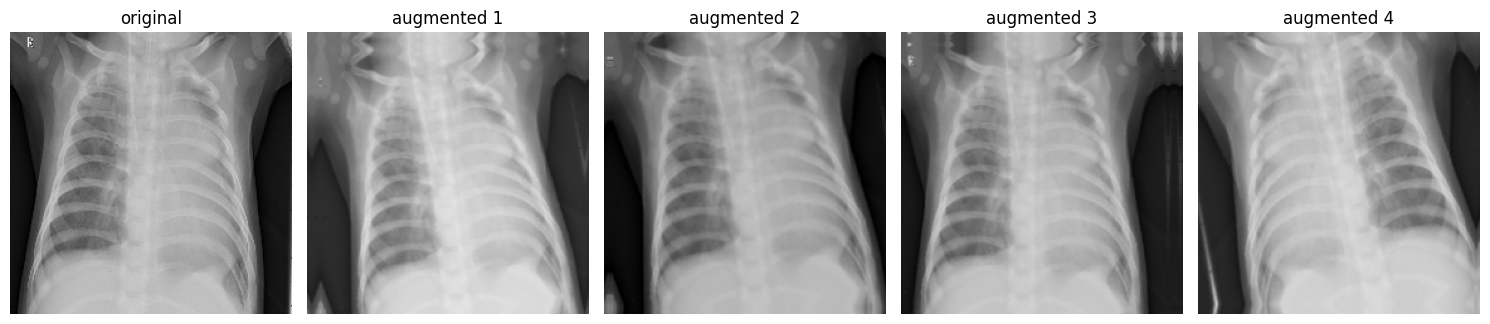

In [ ]:
def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)          # grayscale -> 3 channels
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))     # pixel range stays 0-255 here
    return img, tf.expand_dims(tf.cast(label, tf.float32), -1)

def make_ds(p, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(tr_p, tr_y, True)
val_ds = make_ds(va_p, va_y, False)
test_ds = make_ds(te_p, te_y, False)

def make_augment():
    return models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),                 # about +-11 degrees
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomBrightness(0.1, value_range=(0, 255)),
    ], name="augmentation")

augment = make_augment()

# Show what augmentation does to one training image
img0, _ = next(iter(train_ds.unbatch().take(1)))
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(img0.numpy().astype("uint8")); axes[0].set_title("original")
for k in range(1, 5):
    axes[k].imshow(augment(tf.expand_dims(img0, 0), training=True)[0].numpy().astype("uint8"))
    axes[k].set_title(f"augmented {k}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Custom CNN Architecture
The network is a compact VGG-style CNN built from four convolutional blocks. Each block applies two `Conv2D (3x3) -> Batch Normalisation -> ReLU` units and ends with `MaxPooling (2x2)`.

| Stage | Layers | Output role |
|---|---|---|
| Input | 224 x 224 x 3 image, augmentation (training only), `Rescaling(1/255)` | normalised input |
| Block 1 | 2 x Conv(32) + BN + ReLU, MaxPool | low-level edges and textures |
| Block 2 | 2 x Conv(64) + BN + ReLU, MaxPool | local patterns |
| Block 3 | 2 x Conv(128) + BN + ReLU, MaxPool | larger structures |
| Block 4 | 2 x Conv(256) + BN + ReLU, MaxPool | high-level features |
| Classifier | Global Average Pooling, Dense(128, ReLU), Dropout(0.4), Dense(1, sigmoid) | probability of PNEUMONIA |

**Design choices.**
- **Increasing filters (32 to 256)** let the network learn simple features first and more abstract features deeper in the network.
- **Batch normalisation** stabilises and speeds up training from random initialisation. The convolutions use `use_bias=False` because batch normalisation already has its own offset term.
- **ReLU** provides non-linearity and avoids vanishing gradients.
- **Global average pooling** replaces large flatten layers, which greatly reduces the number of parameters and the risk of overfitting.
- **Dropout (0.4)** before the output layer further regularises the classifier.
- A **sigmoid output** is used because the task is binary.



In [ ]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    return x

def build_cnn():
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = conv_block(x, f)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, out, name=MODEL_NAME)
    model.compile(optimizer=Adam(LEARNING_RATE), loss="binary_crossentropy", metrics=["accuracy"])
    return model

model = build_cnn()
model.summary()
print(f"Trainable parameters: {int(np.sum([np.prod(w.shape) for w in model.trainable_weights])):,}")

Model: "CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,161 (4.61 MB)

 Trainable params: 1,206,241 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

Trainable parameters: 1,206,241


## 4. Training with Early Stopping
The model is trained with the binary cross-entropy loss and the Adam optimiser. Three callbacks control training:

- **EarlyStopping** monitors the **validation loss** and stops training after **7 epochs without improvement**. As required, it can only act **after the first 5 epochs** (`start_from_epoch=5`), so the model always trains for at least 5 epochs. It restores the weights of the best epoch.
- **ModelCheckpoint** saves the weights with the lowest validation loss.
- **ReduceLROnPlateau** multiplies the learning rate by 0.3 when the validation loss stops improving for 3 epochs, which allows finer convergence.

**Class weights** compensate for the class imbalance. The total training time and the test (inference) time are both measured, so they can be compared with the pretrained models in Submission 2.

In [ ]:
def run_training():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn()
    ckpt = f"best_{MODEL_NAME}.weights.h5"
    cbs = [EarlyStopping(monitor="val_loss", patience=PATIENCE, start_from_epoch=MIN_EPOCHS,
                         restore_best_weights=True, verbose=1),
           ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True),
           ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
                     class_weight=class_weight, callbacks=cbs, verbose=2)
    train_time = time.time() - t0
    model.load_weights(ckpt)
    model.predict(test_ds.take(1), verbose=0)
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0).ravel()
    test_time = time.time() - t0
    return hist.history, probs, train_time, test_time

history, probs, train_time, test_time = run_training()
print(f"Epochs run: {len(history['loss'])} (minimum required: {MIN_EPOCHS})")

Epoch 1/50
139/139 - 85s - 609ms/step - accuracy: 0.8561 - loss: 0.3250 - val_accuracy: 0.7433 - val_loss: 2.9355 - learning_rate: 0.0010
Epoch 2/50
139/139 - 44s - 319ms/step - accuracy: 0.8926 - loss: 0.2584 - val_accuracy: 0.7433 - val_loss: 1.0558 - learning_rate: 0.0010
Epoch 3/50
139/139 - 44s - 316ms/step - accuracy: 0.9010 - loss: 0.2316 - val_accuracy: 0.2593 - val_loss: 8.7771 - learning_rate: 0.0010
Epoch 4/50
139/139 - 44s - 314ms/step - accuracy: 0.9170 - loss: 0.2145 - val_accuracy: 0.2810 - val_loss: 4.7661 - learning_rate: 0.0010
Epoch 5/50
139/139 - 44s - 315ms/step - accuracy: 0.9204 - loss: 0.1940 - val_accuracy: 0.9119 - val_loss: 0.2513 - learning_rate: 0.0010
Epoch 6/50
139/139 - 44s - 316ms/step - accuracy: 0.9296 - loss: 0.1699 - val_accuracy: 0.3244 - val_loss: 2.0611 - learning_rate: 0.0010
Epoch 7/50
139/139 - 46s - 331ms/step - accuracy: 0.9366 - loss: 0.1679 - val_accuracy: 0.7178 - val_loss: 0.8740 - learning_rate: 0.0010
Epoch 8/50

Epoch 8: ReduceLROnPla

## 5. Evaluation on the Test Set
The model with the best validation loss is evaluated on the **624 unseen test images**. The following results are reported, using the same metrics as in Submission 2:

- **Accuracy and loss curves** for the training and validation sets. The dashed vertical line marks the best epoch. A growing gap between the two curves indicates overfitting.
- **Classification report:** precision, recall and F1-score for each class.
- **Confusion matrix:** the numbers of true and false predictions.
- **Fit check:** a simple comparison of training and validation accuracy at the best epoch to flag overfitting or underfitting.
- **Training time and testing time.**

In a medical screening setting, **recall for PNEUMONIA** (the fraction of sick patients detected) is especially important, because a missed case (false negative) is more harmful than a false alarm.

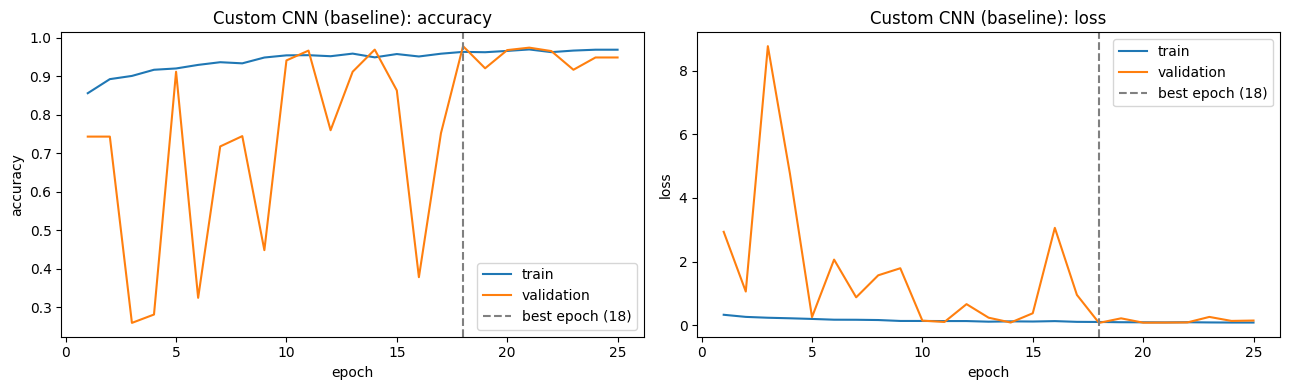

Classification report - Custom CNN (baseline) (test set, 624 images)
              precision    recall  f1-score   support

      NORMAL     0.9863    0.3077    0.4691       234
   PNEUMONIA     0.7060    0.9974    0.8268       390

    accuracy                         0.7388       624
   macro avg     0.8461    0.6526    0.6479       624
weighted avg     0.8111    0.7388    0.6926       624



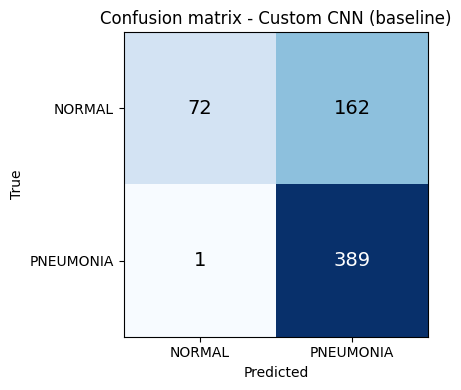

Fit check at the best epoch: no strong sign of over- or underfitting (train 0.963, validation 0.978)
Training time: 1315.6 s (21.9 min) | Testing time: 4.64 s


In [ ]:
def report(title, history, probs, train_time, test_time):
    y_true = te_y
    y_pred = (probs >= 0.5).astype(int)
    epochs = range(1, len(history["loss"]) + 1)
    best = int(np.argmin(history["val_loss"]))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(epochs, history["accuracy"], label="train")
    ax[0].plot(epochs, history["val_accuracy"], label="validation")
    ax[0].axvline(best + 1, ls="--", color="grey", label=f"best epoch ({best + 1})")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend()
    ax[1].plot(epochs, history["loss"], label="train")
    ax[1].plot(epochs, history["val_loss"], label="validation")
    ax[1].axvline(best + 1, ls="--", color="grey", label=f"best epoch ({best + 1})")
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

    print(f"Classification report - {title} (test set, {len(y_true)} images)")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.6, 4))
    plt.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    plt.xticks([0, 1], CLASSES); plt.yticks([0, 1], CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix - {title}")
    plt.tight_layout(); plt.show()

    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1)
    tr_acc, va_acc = history["accuracy"][best], history["val_accuracy"][best]
    gap = tr_acc - va_acc
    if gap > 0.05:
        diag = f"possible OVERFITTING (train accuracy {tr_acc:.3f} is {gap:.3f} above validation {va_acc:.3f})"
    elif tr_acc < 0.85 and va_acc < 0.85:
        diag = f"possible UNDERFITTING (train {tr_acc:.3f}, validation {va_acc:.3f} are both low)"
    else:
        diag = f"no strong sign of over- or underfitting (train {tr_acc:.3f}, validation {va_acc:.3f})"
    print("Fit check at the best epoch:", diag)
    print(f"Training time: {train_time:.1f} s ({train_time / 60:.1f} min) | Testing time: {test_time:.2f} s")

    return dict(model=MODEL_NAME, mode=title, epochs_run=len(epochs), best_epoch=best + 1,
                train_acc=round(tr_acc, 4), val_acc=round(va_acc, 4),
                test_accuracy=round(accuracy_score(y_true, y_pred), 4),
                precision=round(p, 4), recall=round(r, 4), f1=round(f, 4),
                auc=round(roc_auc_score(y_true, probs), 4),
                train_time_s=round(train_time, 1), test_time_s=round(test_time, 2))

res_cnn = report("Custom CNN (baseline)", history, probs, train_time, test_time)

## 6. Summary of Results
The table collects all test-set metrics in one place, including the number of epochs actually run, the best epoch, the AUC (area under the ROC curve), and the training and testing time. The bar chart visualises accuracy, precision, recall, F1-score and AUC. This table is the reference baseline that the attention-based model in Submission 4 will be compared against.

mode,Custom CNN (baseline)
model,CustomCNN
epochs_run,25
best_epoch,18
train_acc,0.9635
val_acc,0.9783
test_accuracy,0.7388
precision,0.706
recall,0.9974
f1,0.8268
auc,0.9358


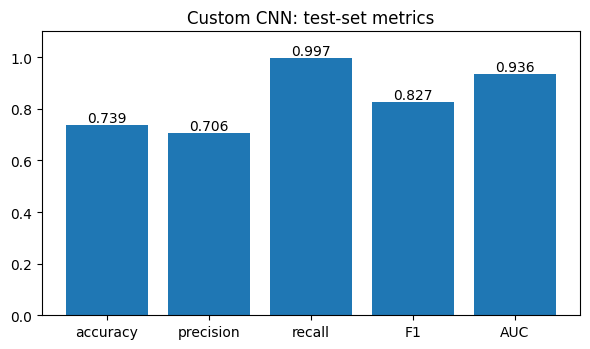

In [ ]:
results = pd.DataFrame([res_cnn]).set_index("mode")
display(results.T)
results.to_csv("results_CustomCNN.csv")

fig, ax = plt.subplots(figsize=(6, 3.6))
metrics = ["test_accuracy", "precision", "recall", "f1", "auc"]
vals = [results.iloc[0][m] for m in metrics]
ax.bar(["accuracy", "precision", "recall", "F1", "AUC"], vals, color="#1f77b4")
for i, v in enumerate(vals): ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1.1); ax.set_title("Custom CNN: test-set metrics")
plt.tight_layout(); plt.show()

## 7. Discussion

### How overfitting was controlled
- **Early stopping** on the validation loss (minimum 5 epochs, patience 7), with the best-epoch weights restored.
- **Dropout (0.4)**, **batch normalisation** and **data augmentation** act as regularisers.
- **Class weights** reduce the bias towards the majority class.
- **Learning-rate reduction** on plateau stabilises late training.
- Training and validation loss are plotted together, and the fit check compares training and validation accuracy at the best epoch.

### Observations

**Training and early stopping.** The custom CNN ran for 25 epochs. Early stopping fired after 7 epochs without improvement in validation loss, and the weights of epoch 18 were restored, so the minimum of 5 epochs was clearly satisfied. The learning rate was reduced four times by `ReduceLROnPlateau`. Training took 1315.6 s (21.9 min) and testing 4.64 s.

**Results on the test set (624 images).** Accuracy 0.7388, precision 0.7060, recall 0.9974, F1-score 0.8268 and AUC 0.9358.

**Errors.** The confusion matrix shows 72 true NORMAL, 162 false PNEUMONIA, 1 missed PNEUMONIA and 389 true PNEUMONIA. PNEUMONIA recall is 0.9974 (only 1 of 390 missed), but NORMAL recall is only 0.3077, so 162 of 234 healthy X-rays were wrongly flagged. The model therefore prefers false alarms to missed cases. This is the same pattern we saw with the pretrained models in Submission 2.

**Training behaviour.** The training curves are smooth: training accuracy rose steadily from about 0.86 to about 0.97 and training loss fell steadily. The validation curves, however, are very unstable during the first 17 epochs. Validation accuracy jumped between about 0.26 and 0.97 and validation loss spiked to about 8.8 in epoch 3 and about 3 in epoch 16. A likely reason is that batch normalisation, which keeps running statistics, behaves differently between training and evaluation while the weights are still changing quickly, but we did not test this. Validation became stable only after the learning rate had been reduced several times (about epoch 18), and early stopping restored the weights of epoch 18, so the unstable epochs did not affect the final model.

**Overfitting and underfitting.** At the best epoch, training accuracy (0.9635) and validation accuracy (0.9783) are close, so the fit check shows no strong sign of overfitting or underfitting. However, validation accuracy (0.978) is much higher than test accuracy (0.739). Our validation set comes from the same folder as the training images, while the official test set is separate, so the validation score is too optimistic. We did not check whether images of the same patient appear in both our training and validation parts.

**Comparison with the pretrained models.** The custom CNN has a lower test accuracy (0.7388) than the pretrained models of Submission 2 (0.7676 to 0.8558) and a slightly lower AUC (0.9358, compared with 0.9456 to 0.9727). This is expected, because it has only about 1.2 million parameters and no ImageNet knowledge. It also trained faster (21.9 min), because early stopping ended training after 25 of 50 possible epochs, whereas the Submission 2 models ran for 40 epochs per mode. Its high recall is useful for screening, but the many false alarms would need further work, for example a different decision threshold. This model is the baseline for Submission 4.

## References
1. D. S. Kermany et al., "Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning," *Cell*, vol. 172, no. 5, pp. 1122-1131, 2018. Dataset: Kaggle, *Chest X-Ray Images (Pneumonia)*, paultimothymooney/chest-xray-pneumonia (CC BY 4.0).
2. D. P. Kingma and J. Ba, "Adam: A Method for Stochastic Optimization," *arXiv:1412.6980*, 2014.
3. S. Ioffe and C. Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift," *ICML*, 2015.
4. N. Srivastava et al., "Dropout: A Simple Way to Prevent Neural Networks from Overfitting," *JMLR*, vol. 15, 2014.